<a href="https://colab.research.google.com/github/Sphesihle12389/Nombika-S__22312280/blob/main/S_Nombika_22312280.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TLPR200 — Supp Exam
## Identifying Women-Safety Hotspots and Crime Patterns in the City of Ekurhuleni


## Student Information
* **Surname & Initials:** Nombika, S.
* **Student Number:** `22312280`
* **Module:** `TLPR200`


## Project Overview
Recent discoveries of the bodies of women in Kempton Park and other parts of Ekurhuleni have raised urgent questions about where violent crime is concentrated, when it peaks, and what local conditions are associated with higher risk.

In this project, I analyse historical crime records, police boundary maps, and public transport data across the 39 police precincts in the City of Ekurhuleni:
1. **Real Public Data:** I use official quarterly crime reports and police station boundary maps from the South African Police Service (SAPS), combined with public transport and infrastructure locations from OpenStreetMap.
2. **Women-Safety Proxy Index:** SAPS station spreadsheets report total crimes per offence category without separating victims by sex. Rather than claiming all recorded crimes are exclusively against women, I combine the four violent contact crimes that most directly affect women's safety: **Murder**, **Sexual Offences**, **Assault GBH**, and **Common Assault**.
3. **Ethical Interpretation:** Identifying a precinct as a hotspot is a way to prioritise street lighting, safer commuter walkways, visible policing, and victim support resources—not a label that a community or its residents are inherently dangerous.

---

### Datasets Used

| Dataset | Source Link | Geographic Level | Time Period | Variables Used | Limitations |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **SAPS Quarterly Crime Statistics** (`5 Workbooks`) | [https://www.saps.gov.za/services/crimestats.php](https://www.saps.gov.za/services/crimestats.php) | Police Station Precinct (`39 stations` in Ekurhuleni) | **21 Quarters** (`April 2021 – June 2026`) | Quarterly counts of reported violent crimes per station. | Under-reporting of gender-based violence; victim sex is not disaggregated in SAPS station releases. |
| **SAPS Police Station Boundaries** (`Police_bounds.shp`) | [https://www.saps.gov.za/services/boundary.php](https://www.saps.gov.za/services/boundary.php) | Police Station Polygon (`39 Ekurhuleni polygons`) | Release `v1.4.2` | Land area ($\text{km}^2$), border length, shape compactness, and neighbouring stations. | Precinct sizes vary widely ($8.5\text{ km}^2$ to $385\text{ km}^2$) and do not measure daytime commuter inflows vs. night-time residents. |
| **OpenStreetMap Transport & Infrastructure** (`OSMnx`) | [https://www.openstreetmap.org](https://www.openstreetmap.org) | Points & buildings inside each precinct | Current snapshot | Bus stops, train stations, taxi ranks, crossings, shops, schools, and clinics. | Commercial town centres often have more mapped shops on OpenStreetMap than informal settlements. |

---
## Loading Libraries and Finding the Data Files

### Load Basic Python File and Text Helpers
I start by importing Python's built-in modules for working with file paths (`os`, `glob`), text patterns (`re`), Excel XML files (`zipfile`, `ET`), and JSON files (`json`).

In [ ]:
import os
import re
import glob
import json
import zipfile
import warnings
import xml.etree.ElementTree as ET

warnings.filterwarnings('ignore')
print("Basic file and text helpers loaded.")

Basic file and text helpers loaded.


### Load Data Table and Map Libraries
Next, I import `numpy` and `pandas` for working with data tables, along with `geopandas` and `osmnx` for handling police boundary maps and OpenStreetMap locations.

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox

print("Table and map libraries (pandas, geopandas, osmnx) loaded.")

Table and map libraries (pandas, geopandas, osmnx) loaded.


### Load Charting and Machine Learning Libraries
Here I import `matplotlib` and `seaborn` to draw charts and maps, and `scikit-learn` to build and test my machine learning and clustering models.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    silhouette_score
)

plt.style.use('seaborn-v0_8-whitegrid')
print("Charting and machine learning tools ready.")

Charting and machine learning tools ready.


### Locate the SAPS Excel Files and Boundary Map on Disk
I set up the file paths to locate the 5 SAPS quarterly crime spreadsheets and the `Police_bounds.shp` boundary map in the project folder.

In [ ]:
if os.path.exists('station_boundaries/Police_bounds.shp'):
    BASE_DIR = '.'
    SHP_PATH = 'station_boundaries/Police_bounds.shp'
else:
    BASE_DIR = '/content/drive/MyDrive/TP2SuppExam'
    SHP_PATH = os.path.join(BASE_DIR, 'station_boundaries_points/station_boundaries_points/station_boundaries/station_boundaries/Police_bounds.shp')

excel_files = sorted(glob.glob(os.path.join(BASE_DIR, "*.xlsx")) + glob.glob(os.path.join(BASE_DIR, "*.xlsm")))

### Print the List of Data Files Found
I print out the shapefile path and the names of the 5 SAPS Excel files to confirm they are all found before loading them.

In [ ]:
print(f"Boundary Shapefile Found : {os.path.exists(SHP_PATH)} ({SHP_PATH})")
print(f"SAPS Excel Files Found   : {len(excel_files)} files")
for f in excel_files:
    print("  ->", os.path.basename(f))

Boundary Shapefile Found : True (station_boundaries/Police_bounds.shp)
SAPS Excel Files Found   : 5 files
  -> 2025-2026_-_1st_Quarter_WEB.xlsx
  -> 2025-2026_-_2nd_Quarter_WEB.xlsx
  -> 2025-2026_-_3rd_Quarter_WEB.xlsx
  -> 2025-2026_-_4th_Quarter_WEB.xlsx
  -> 2026-2027_-_1st_Quarter_WEB.xlsm


---
## Reading and Cleaning the SAPS Crime Spreadsheets

### Choose Which Crime Categories to Extract
In the SAPS spreadsheets, `Sexual offences` is already the combined total of `Rape`, `Sexual assault`, and related offences. To avoid counting the same crime twice, I use the **4 headline violent contact crimes** (`Murder`, `Sexual_Offences`, `Assault_GBH`, and `Common_Assault`) for my main Women-Safety Proxy total, and keep **5 detailed sub-categories** separate for filtering in the dashboard.

In [ ]:
TARGET_OFFENCES = {
    'Murder': 'Murder',
    'Sexual offences': 'Sexual_Offences',
    'Assault with the intent to inflict grievous bodily harm': 'Assault_GBH',
    'Common assault': 'Common_Assault',
    'Rape': 'Rape',
    'Sexual assault': 'Sexual_Assault',
    'Attempted murder': 'Attempted_Murder',
    'Kidnapping': 'Kidnapping',
    'Abduction': 'Abduction'
}

PRIMARY_PROXY_KEYS = ['Murder', 'Sexual_Offences', 'Assault_GBH', 'Common_Assault']
print("Main Proxy Categories:", PRIMARY_PROXY_KEYS)

Main Proxy Categories: ['Murder', 'Sexual_Offences', 'Assault_GBH', 'Common_Assault']


### Create a Helper to Turn SAPS Date Text into Clean Quarters and Seasons
Each SAPS spreadsheet column header describes a 3-month period such as `"October 2025 to December 2025"`. I wrote this helper function to extract the year, the quarter number, and the season (`Autumn/Winter`, `Winter/Spring`, `Summer/Festive`, or `Late Summer`) so I can sort the timeline properly.

In [ ]:
def parse_quarter_metadata(q_label):
    q_clean = re.sub(r'\s+', ' ', q_label).strip()
    m = re.match(r'([A-Za-z]+)\s+(\d{4})\s+to\s+([A-Za-z]+)\s+(\d{4})', q_clean)
    start_month, start_yr, end_month = m.group(1), int(m.group(2)), m.group(3)
    season_map = {
        'April':   (2, 1, 'Autumn/Winter (Apr-Jun)'),
        'July':    (3, 2, 'Winter/Spring (Jul-Sep)'),
        'October': (4, 3, 'Summer/Festive (Oct-Dec)'),
        'January': (1, 4, 'Late Summer (Jan-Mar)')
    }
    cal_q, fin_q, season = season_map[start_month]
    return q_clean, start_yr, cal_q, fin_q, season, f"{start_yr}-{cal_q:02d}", f"{start_yr} Q{cal_q} ({start_month[:3]}-{end_month[:3]})"

print("Sample date conversion:", parse_quarter_metadata("October 2025 to December 2025")[-1])

Sample date conversion: 2025 Q4 (Oct-Dec)


### Create a Reader for the `'RAW Data'` Sheet Inside Each SAPS File
In the SAPS Excel files, the first sheet is `'Lookup lists'` and the actual station numbers are on the second sheet (`'RAW Data'`), with the column headers sitting on Row 3. This function reads `'RAW Data'`, filters for `'Ekurhuleni District'`, and extracts only the 5 quarterly total columns (`M, Q, U, Y, AC`).

In [ ]:
def load_saps_workbook(filepath):
    records, missing_cells = [], 0
    with zipfile.ZipFile(filepath) as z:
        ss = ET.fromstring(z.read('xl/sharedStrings.xml'))
        strings = [''.join(t.itertext()) for t in ss.iter('{http://schemas.openxmlformats.org/spreadsheetml/2006/main}si')]
        s2 = ET.fromstring(z.read('xl/worksheets/sheet2.xml'))
        for i, row in enumerate(s2.iter('{http://schemas.openxmlformats.org/spreadsheetml/2006/main}row')):
            vals = {''.join(ch for ch in c.attrib.get('r', '') if ch.isalpha()): (strings[int(v.text)] if c.attrib.get('t') == 's' else v.text).strip()
                    for c in row if (v := c.find('{http://schemas.openxmlformats.org/spreadsheetml/2006/main}v')) is not None and v.text is not None}
            if i == 2:
                q_cols = {k: vals[k].replace('\n', ' ').strip() for k in ['M', 'Q', 'U', 'Y', 'AC'] if k in vals}
            elif i > 2 and vals.get('F') == 'Ekurhuleni District' and vals.get('C') == 'Station' and vals.get('H', '') in TARGET_OFFENCES:
                st, off = vals['E'].strip(), vals['H']
                for q_col, q_label in q_cols.items():
                    raw_val = vals.get(q_col, '')
                    missing_cells += int(raw_val == '')
                    q_clean, yr, cal_q, fin_q, season, sort_key, short_lbl = parse_quarter_metadata(q_label)
                    records.append({'Station': st, 'match_name': st.upper(), 'Crime_Category': off, 'Category_Key': TARGET_OFFENCES[off],
                                    'Is_Primary_Proxy': TARGET_OFFENCES[off] in PRIMARY_PROXY_KEYS, 'Quarter_Label': q_clean, 'Quarter_Short': short_lbl,
                                    'Sort_Key': sort_key, 'Year': yr, 'Calendar_Quarter': cal_q, 'SAPS_Fin_Quarter': fin_q, 'Season': season, 'Incidents': float(raw_val or 0.0)})
    return pd.DataFrame(records), missing_cells

### Load All Five SAPS Spreadsheets into One Table
I loop through all 5 SAPS Excel files using my reader function and combine the extracted Ekurhuleni station rows into a single table.

In [ ]:
raw_parts, total_missing = [], 0
for fp in excel_files:
    part_df, miss = load_saps_workbook(fp)
    raw_parts.append(part_df)
    total_missing += miss
    print(f"Read {os.path.basename(fp):<35} -> {len(part_df):,d} Ekurhuleni records")

raw_all_df = pd.concat(raw_parts, ignore_index=True)

Read 2025-2026_-_1st_Quarter_WEB.xlsx    -> 1,755 Ekurhuleni records


Read 2025-2026_-_2nd_Quarter_WEB.xlsx    -> 1,755 Ekurhuleni records


Read 2025-2026_-_3rd_Quarter_WEB.xlsx    -> 1,755 Ekurhuleni records


Read 2025-2026_-_4th_Quarter_WEB.xlsx    -> 1,755 Ekurhuleni records


Read 2026-2027_-_1st_Quarter_WEB.xlsm    -> 1,755 Ekurhuleni records


### Remove Duplicate Overlapping Quarters
Because each SAPS spreadsheet includes a 5-year historical comparison, the `2025/26 Q1` file and the `2026/27 Q1` file both contain the April–June numbers for 2022 to 2025. Here I remove those duplicate overlapping quarters so every `(Station, Crime Category, Quarter)` is counted only once.

In [ ]:
duplicate_rows = raw_all_df.duplicated(subset=['match_name', 'Category_Key', 'Quarter_Label']).sum()

saps_long_df = (
    raw_all_df
    .drop_duplicates(subset=['match_name', 'Category_Key', 'Quarter_Label'], keep='last')
    .sort_values(['Sort_Key', 'match_name', 'Category_Key'])
    .reset_index(drop=True)
)

### Print the Data Quality Summary
I print a summary of the cleaned dataset to check how many rows were read, how many overlapping duplicates were removed, whether any numbers were missing, and the total number of stations and quarters covered.

In [ ]:
print("=== DATA QUALITY REPORT ===")
print(f"Total rows before cleaning        : {len(raw_all_df):,d}")
print(f"Overlapping duplicate rows removed: {duplicate_rows:,d}")
print(f"Final clean rows kept             : {len(saps_long_df):,d}")
print(f"Missing numeric values found      : {total_missing}")
print(f"Ekurhuleni Police Stations found  : {saps_long_df['match_name'].nunique()} stations")
print(f"Quarterly periods covered         : {saps_long_df['Quarter_Short'].nunique()} quarters ({saps_long_df['Quarter_Short'].iloc[0]} to {saps_long_df['Quarter_Short'].iloc[-1]})")

=== DATA QUALITY REPORT ===
Total rows before cleaning        : 8,775
Overlapping duplicate rows removed: 1,404
Final clean rows kept             : 7,371
Missing numeric values found      : 0
Ekurhuleni Police Stations found  : 39 stations
Quarterly periods covered         : 21 quarters (2021 Q2 (Apr-Jun) to 2026 Q2 (Apr-Jun))


### Add Up the 4 Women-Safety Proxy Crimes for Each Station
I group the cleaned records by police station and sum `Murder`, `Sexual_Offences`, `Assault_GBH`, and `Common_Assault` across all 21 quarters to get each station's `women_safety_proxy_total`.

In [ ]:
proxy_long_df = saps_long_df[saps_long_df['Is_Primary_Proxy']].copy()

station_category_pivot = proxy_long_df.pivot_table(
    index=['Station', 'match_name'], columns='Category_Key', values='Incidents', aggfunc='sum'
).reset_index()
station_category_pivot['women_safety_proxy_total'] = station_category_pivot[PRIMARY_PROXY_KEYS].sum(axis=1)

sub_pivot = saps_long_df[~saps_long_df['Is_Primary_Proxy']].pivot_table(
    index='match_name', columns='Category_Key', values='Incidents', aggfunc='sum'
).reset_index()

station_crime_df = station_category_pivot.merge(sub_pivot, on='match_name', how='left')

### Check for Unusually High Crime Totals (Outliers)
I use the Interquartile Range (IQR) rule to check whether any police stations have unusually high 21-quarter crime totals compared to the rest of Ekurhuleni.

In [ ]:
q25, q75 = station_crime_df['women_safety_proxy_total'].quantile([0.25, 0.75])
upper_fence = q75 + 1.5 * (q75 - q25)
outliers = station_crime_df[station_crime_df['women_safety_proxy_total'] > upper_fence]['Station'].tolist()

print(f"25th Percentile: {q25:,.0f} | Median: {station_crime_df['women_safety_proxy_total'].median():,.0f} | 75th Percentile: {q75:,.0f}")
print(f"Extreme High-Volume Outlier Stations (> {upper_fence:,.0f} incidents): {outliers}")

25th Percentile: 1,713 | Median: 2,847 | 75th Percentile: 4,853
Extreme High-Volume Outlier Stations (> 9,563 incidents): ['Ivory Park', 'Tembisa']


### Display the Top 10 Police Stations by Raw Crime Count
Here I display the 10 Ekurhuleni police stations with the highest raw number of recorded Women-Safety Proxy crimes between April 2021 and June 2026.

In [ ]:
display(
    station_crime_df[['Station', 'Murder', 'Sexual_Offences', 'Assault_GBH', 'Common_Assault', 'women_safety_proxy_total']]
    .sort_values('women_safety_proxy_total', ascending=False)
    .head(10)
)

Category_Key,Station,Murder,Sexual_Offences,Assault_GBH,Common_Assault,women_safety_proxy_total
33,Tembisa,542.0,974.0,4478.0,4665.0,10659.0
19,Ivory Park,852.0,1079.0,4665.0,3298.0,9894.0
9,Daveyton,400.0,669.0,3142.0,2837.0,7048.0
37,Vosloorus,406.0,643.0,2243.0,3463.0,6755.0
36,Tsakane,436.0,913.0,2726.0,2641.0,6716.0
17,Etwatwa,241.0,587.0,3586.0,1506.0,5920.0
14,Edenpark,334.0,509.0,2447.0,2095.0,5385.0
20,Katlehong,303.0,602.0,2026.0,2283.0,5214.0
34,Tembisa South,444.0,519.0,2113.0,1955.0,5031.0
32,Springs,260.0,587.0,1164.0,2842.0,4853.0


---
## Combining Crime Data with Maps and Public Transport

### Load the Official Police Station Boundary Map (`Police_bounds.shp`)
Comparing raw crime numbers alone can be misleading because some police stations cover huge areas while others cover compact neighbourhoods. Here I load the SAPS boundary shapefile and filter it to the 39 Ekurhuleni stations.

In [ ]:
police_boundaries = gpd.read_file(SHP_PATH)
police_boundaries['match_name'] = police_boundaries['COMPNT_NM'].astype(str).str.upper().str.strip()
ek_boundaries = police_boundaries[police_boundaries['match_name'].isin(station_crime_df['match_name'])].copy()

### Confirm All 39 Ekurhuleni Stations Matched the Map
I check that all 39 Ekurhuleni police stations from the crime spreadsheets matched the boundary shapefile (`100% match`) and preview the first 5 rows.

In [ ]:
print(f"Successfully matched {len(ek_boundaries)} out of {len(station_crime_df)} Ekurhuleni police stations (100% match)!")
display(ek_boundaries[['COMPNT_NM', 'CREATE_DT', 'VERSION', 'geometry']].head(5))

Successfully matched 39 out of 39 Ekurhuleni police stations (100% match)!


,COMPNT_NM,CREATE_DT,VERSION,geometry
12,KWA THEMA,20251205,1.4.2,"POLYGON ((28.4274 -26.30962, 28.42801 -26.3170..."
13,BRAKPAN,20251205,1.4.2,"POLYGON ((28.30798 -26.26218, 28.30749 -26.260..."
31,KATLEHONG,20251205,1.4.2,"POLYGON ((28.20057 -26.38384, 28.19153 -26.390..."
62,SPRINGS,20251205,1.4.2,"POLYGON ((28.58115 -26.23781, 28.62227 -26.248..."
194,PRIMROSE,20251205,1.4.2,"POLYGON ((28.20083 -26.1777, 28.20069 -26.1781..."


### Convert Map to Metric Coordinates and Measure Land Area ($\text{km}^2$)
Standard GPS coordinates are in degrees, so I project the boundary map to South Africa's metric coordinate grid (**UTM Zone 35S, `EPSG:32735`**) and calculate each station's land area in square kilometres (`area_sq_km`), border length (`perimeter_km`), and shape compactness.

In [ ]:
ek_projected = ek_boundaries.to_crs(epsg=32735).reset_index(drop=True)
ek_projected['area_sq_km'] = ek_projected.geometry.area / 1e6
ek_projected['perimeter_km'] = ek_projected.geometry.length / 1e3
ek_projected['shape_compactness'] = (4 * np.pi * ek_projected['area_sq_km']) / (ek_projected['perimeter_km'] ** 2)

### Count Neighbouring Stations and Distance to the City Centre
I also count how many other Ekurhuleni police precincts touch each station's border (`adjacent_precincts`) and measure each station's distance in kilometres from the centre of Ekurhuleni (`dist_to_metro_center_km`).

In [ ]:
ek_projected['adjacent_precincts'] = [int(ek_projected.geometry.touches(g).sum()) for g in ek_projected.geometry]
metro_center = ek_projected.union_all().centroid
ek_projected['dist_to_metro_center_km'] = ek_projected.geometry.centroid.distance(metro_center) / 1e3

ek_wgs84 = ek_projected.to_crs(epsg=4326)
ek_projected['latitude'] = ek_wgs84.geometry.centroid.y
ek_projected['longitude'] = ek_wgs84.geometry.centroid.x

### Display the Smallest and Largest Police Precincts by Land Area
I print the 5 smallest and 5 largest Ekurhuleni police precincts to show the huge difference in land size across the metro ($8.49\text{ km}^2$ in Tokoza vs. $385.37\text{ km}^2$ in Springs).

In [ ]:
print("--- 5 Smallest (Most Compact) Precincts in Ekurhuleni ---")
display(ek_projected[['COMPNT_NM', 'area_sq_km', 'perimeter_km', 'adjacent_precincts']].sort_values('area_sq_km').head(5))

print("--- 5 Largest (Most Sprawling) Precincts in Ekurhuleni ---")
display(ek_projected[['COMPNT_NM', 'area_sq_km', 'perimeter_km', 'adjacent_precincts']].sort_values('area_sq_km', ascending=False).head(5))

--- 5 Smallest (Most Compact) Precincts in Ekurhuleni ---


,COMPNT_NM,area_sq_km,perimeter_km,adjacent_precincts
22,TOKOZA,8.487734,14.748221,5
36,TEMBISA SOUTH,8.945917,15.037983,3
17,ACTONVILLE,9.338612,13.357087,3
30,KATLEHONG NORTH,14.229705,17.176565,3
6,DAVEYTON,15.050119,17.722233,4


--- 5 Largest (Most Sprawling) Precincts in Ekurhuleni ---


,COMPNT_NM,area_sq_km,perimeter_km,adjacent_precincts
13,NIGEL,393.006296,110.173958,3
3,SPRINGS,385.370716,113.013863,3
14,DEVON,330.113540,89.896719,1
24,OLIFANTSFONTEIN,196.818705,70.856715,2
1,BRAKPAN,169.145946,67.440468,5


### Load Public Transport Stops and Community Points from OpenStreetMap
Using `OSMnx`, I load mapped bus stops, train stations, taxi ranks, street crossings, shops, schools, and clinics across Ekurhuleni and convert their coordinates to the same metric grid (`EPSG:32735`).

In [ ]:
ox.settings.use_cache = True
ox.settings.log_console = False

osm_tags = {
    "highway": ["bus_stop", "street_lamp", "traffic_signals", "crossing"],
    "public_transport": ["platform", "station", "stop_position"],
    "railway": ["station", "halt", "tram_stop"],
    "amenity": ["taxi", "bus_station", "school", "clinic", "hospital", "police", "marketplace", "bar", "pub", "Nightclub", "fast_food", "fuel", "bank", "atm"],
    "shop": True
}
transport_pois = ox.features_from_polygon(ek_wgs84.union_all().convex_hull, tags=osm_tags)
pois_projected = transport_pois.to_crs(epsg=32735).copy()
pois_projected['geometry'] = pois_projected.geometry.centroid
print(f"Loaded {len(pois_projected):,d} OpenStreetMap transport & community points in Ekurhuleni.")

Loaded 9,400 OpenStreetMap transport & community points in Ekurhuleni.


### Match Each OpenStreetMap Point to Its Police Station (`gpd.sjoin`)
I run a spatial join (`gpd.sjoin`) to check which Ekurhuleni police station boundary each bus stop, train station, taxi rank, or shop falls inside.

In [ ]:
pois_in_precincts = gpd.sjoin(pois_projected, ek_projected[['match_name', 'geometry']], how='inner', predicate='within')
print(f"Matched {len(pois_in_precincts):,d} OpenStreetMap points inside the 39 Ekurhuleni police boundaries.")

Matched 8,431 OpenStreetMap points inside the 39 Ekurhuleni police boundaries.


### Calculate the Transport Density Index for Every Station
I count the number of transport stops and total community points inside each police boundary, then divide by the station's land area (`area_sq_km`) to get the **Transport Density Index** (transport stops per square kilometre).

In [ ]:
total_poi_counts = pois_in_precincts.groupby('match_name').size().reset_index(name='poi_count')
is_trans = (pois_in_precincts['highway'].isin(['bus_stop', 'traffic_signals', 'crossing']) |
            pois_in_precincts['public_transport'].notnull() | pois_in_precincts['railway'].notnull() |
            pois_in_precincts['amenity'].isin(['taxi', 'bus_station', 'fuel']))
transport_counts = pois_in_precincts[is_trans].groupby('match_name').size().reset_index(name='transport_poi_count')

spatial_cols = ['match_name', 'area_sq_km', 'perimeter_km', 'shape_compactness', 'adjacent_precincts', 'dist_to_metro_center_km', 'latitude', 'longitude']
precinct_spatial_df = ek_projected[spatial_cols].merge(total_poi_counts, on='match_name', how='left').merge(transport_counts, on='match_name', how='left').fillna(0)
precinct_spatial_df['transport_density_index'] = precinct_spatial_df['transport_poi_count'] / precinct_spatial_df['area_sq_km']
precinct_spatial_df['poi_density_index'] = precinct_spatial_df['poi_count'] / precinct_spatial_df['area_sq_km']

### Combine Crime Totals and Map Measurements into One Master Table
I merge the SAPS crime table with the map and transport table, then divide `women_safety_proxy_total` by `area_sq_km` to calculate **`proxy_crime_density`** (Women-Safety Proxy crimes per square kilometre).

In [ ]:
final_merged_df = station_crime_df.merge(precinct_spatial_df, on='match_name', how='inner')
final_merged_df['proxy_crime_density'] = final_merged_df['women_safety_proxy_total'] / final_merged_df['area_sq_km']
final_merged_df['annual_proxy_crime_density'] = (final_merged_df['women_safety_proxy_total'] / 5.25) / final_merged_df['area_sq_km']

### Display the Top 10 Stations Ranked by Crime Density per Square Kilometre
Here I display the 10 Ekurhuleni police stations with the highest concentration of Women-Safety Proxy crimes per square kilometre.

In [ ]:
display(
    final_merged_df[['Station', 'area_sq_km', 'women_safety_proxy_total', 'proxy_crime_density', 'transport_density_index', 'poi_count']]
    .sort_values('proxy_crime_density', ascending=False)
    .head(10)
)

,Station,area_sq_km,women_safety_proxy_total,proxy_crime_density,transport_density_index,poi_count
34,Tembisa South,8.945917,5031.0,562.379464,11.625415,118
9,Daveyton,15.050119,7048.0,468.301947,2.192674,68
33,Tembisa,23.595050,10659.0,451.747294,7.755864,264
19,Ivory Park,27.936604,9894.0,354.159014,0.966474,44
35,Tokoza,8.487734,2943.0,346.735666,5.183952,61
21,Katlehong North,14.229705,4201.0,295.227473,8.854716,147
23,Kwa Thema,16.077008,4570.0,284.256879,1.057411,22
29,Rabie Ridge,18.408646,4853.0,263.626126,4.454429,99
37,Vosloorus,28.404128,6755.0,237.817545,2.886904,137
17,Etwatwa,26.667478,5920.0,221.993247,0.112497,20


---
## Exploratory Data Analysis

### Top 15 Stations by Raw Crime Count
I plot a horizontal bar chart of the 15 Ekurhuleni stations with the highest raw number of Women-Safety Proxy crimes over the 21 quarters (`April 2021 – June 2026`). **Tembisa** (`10,659`) and **Ivory Park** (`9,894`) have the highest raw totals.

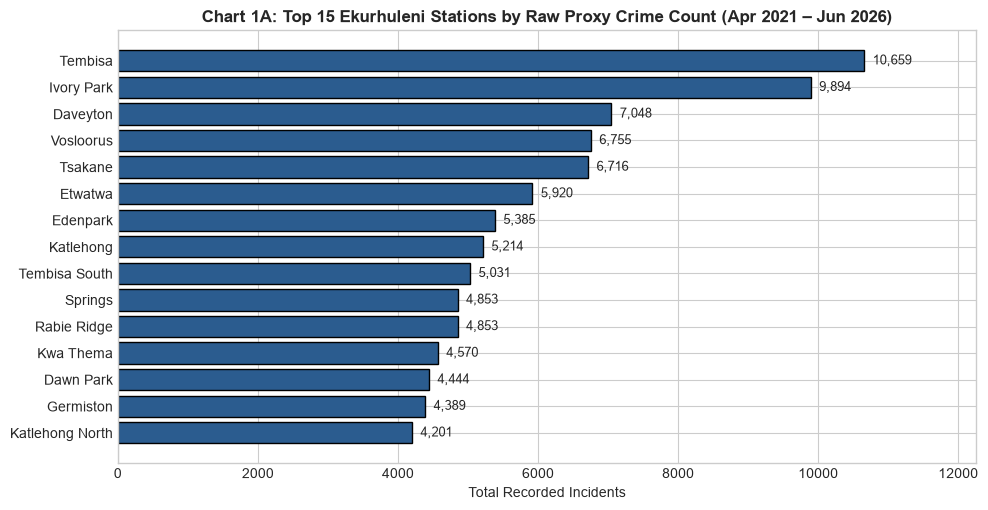

In [ ]:
plt.figure(figsize=(10, 5.2))
top_raw = final_merged_df.sort_values('women_safety_proxy_total', ascending=True).tail(15)
plt.barh(top_raw['Station'], top_raw['women_safety_proxy_total'], color='#2b5c8f', edgecolor='black')
plt.title('Top 15 Ekurhuleni Stations by Raw Proxy Crime Count (Apr 2021 – Jun 2026)', fontsize=12, fontweight='bold')
plt.xlabel('Total Recorded Incidents')
for i, v in enumerate(top_raw['women_safety_proxy_total']):
    plt.text(v + 120, i, f"{int(v):,d}", va='center', fontsize=9)
plt.xlim(0, top_raw['women_safety_proxy_total'].max() * 1.15)
plt.tight_layout()
plt.show()

### Top 15 Stations by Crime Density ($\text{Crimes per km}^2$)
Next, I plot the top 15 stations ranked by **crime density (crimes per $\text{km}^2$)**. Dividing by land area shows that compact townships like **Tembisa South** ($562.4/\text{km}^2$), **Daveyton** ($468.3/\text{km}^2$), and **Tembisa** ($451.8/\text{km}^2$) face the highest spatial concentration of violence.

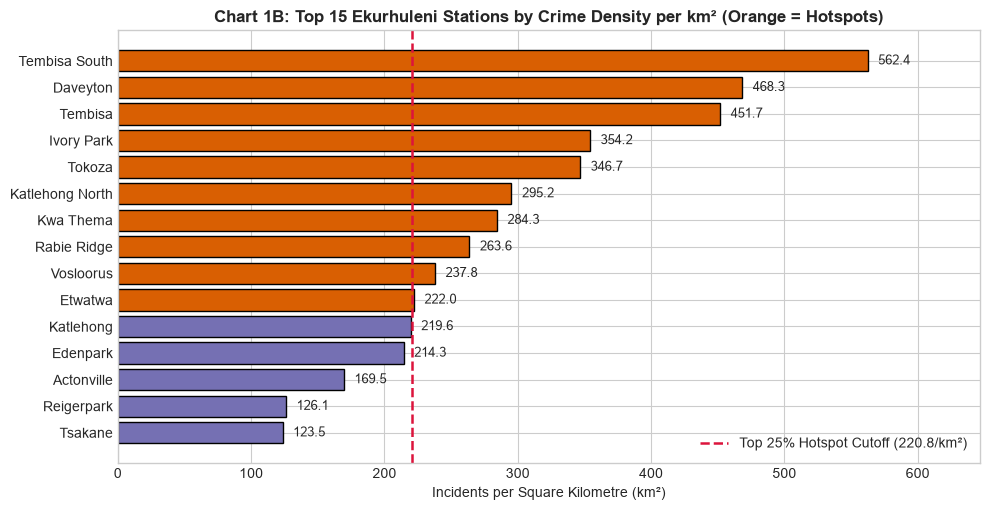

In [ ]:
plt.figure(figsize=(10, 5.2))
thresh_75_val = final_merged_df['proxy_crime_density'].quantile(0.75)
top_dens = final_merged_df.sort_values('proxy_crime_density', ascending=True).tail(15)
colors_dens = ['#d95f02' if x >= thresh_75_val else '#7570b3' for x in top_dens['proxy_crime_density']]
plt.barh(top_dens['Station'], top_dens['proxy_crime_density'], color=colors_dens, edgecolor='black')
plt.axvline(thresh_75_val, color='crimson', linestyle='--', linewidth=1.8, label=f'Top 25% Hotspot Cutoff ({thresh_75_val:.1f}/km²)')
plt.title('Top 15 Ekurhuleni Stations by Crime Density per km² (Orange = Hotspots)', fontsize=12, fontweight='bold')
plt.xlabel('Incidents per Square Kilometre (km²)')
for i, v in enumerate(top_dens['proxy_crime_density']):
    plt.text(v + 8, i, f"{v:.1f}", va='center', fontsize=9)
plt.xlim(0, top_dens['proxy_crime_density'].max() * 1.15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### How Crime Changes Over Time (21 Quarters: April 2021 – June 2026)
I plot the quarterly timeline for all four crime categories from April 2021 to June 2026. I shaded the **October to December (Summer / Festive)** quarters in yellow, which shows a clear, repeating spike in assaults and sexual offences every summer.

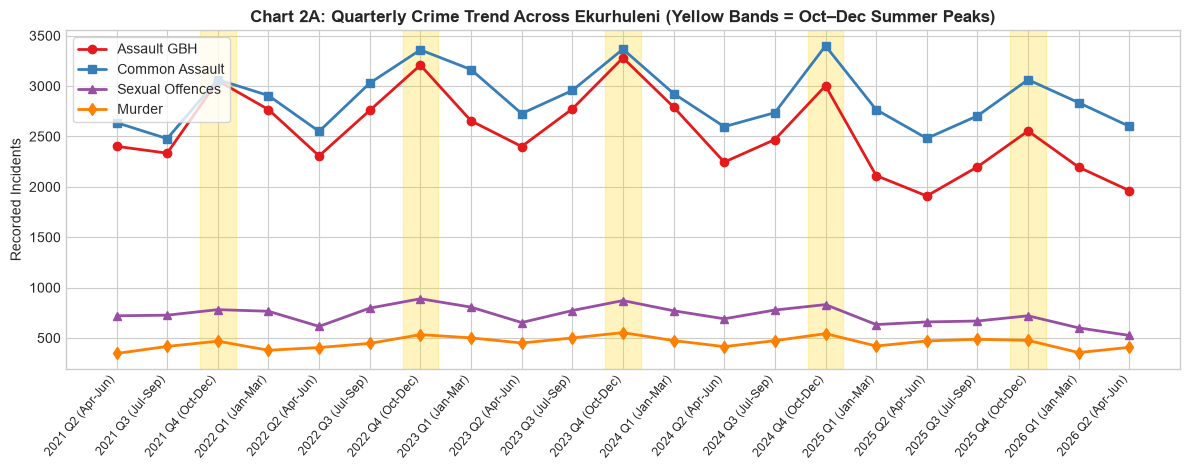

In [ ]:
plt.figure(figsize=(12, 4.8))
q_trend = proxy_long_df.groupby(['Sort_Key', 'Quarter_Short', 'Category_Key'])['Incidents'].sum().unstack('Category_Key').reset_index().sort_values('Sort_Key')
x_idx = np.arange(len(q_trend))
for cat, col, mk in [('Assault_GBH', '#e41a1c', 'o'), ('Common_Assault', '#377eb8', 's'), ('Sexual_Offences', '#984ea3', '^'), ('Murder', '#ff7f00', 'd')]:
    plt.plot(x_idx, q_trend[cat], marker=mk, linewidth=2, label=cat.replace('_', ' '), color=col)
for i, lbl in enumerate(q_trend['Quarter_Short']):
    if 'Oct-Dec' in lbl:
        plt.axvspan(i - 0.35, i + 0.35, color='gold', alpha=0.25)
plt.xticks(x_idx, q_trend['Quarter_Short'], rotation=50, ha='right', fontsize=8.5)
plt.title('Quarterly Crime Trend Across Ekurhuleni (Yellow Bands = Oct–Dec Summer Peaks)', fontsize=12, fontweight='bold')
plt.ylabel('Recorded Incidents')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

### Average Crime Count by Season of the Year
Here I group the 21 quarters by season and plot the average quarterly crime count. Ekurhuleni averages **`6,809` proxy incidents** in `Summer/Festive (Oct-Dec)` compared to **`5,179`** in `Autumn/Winter (Apr-Jun)` — a **31% increase** during the summer festive period.

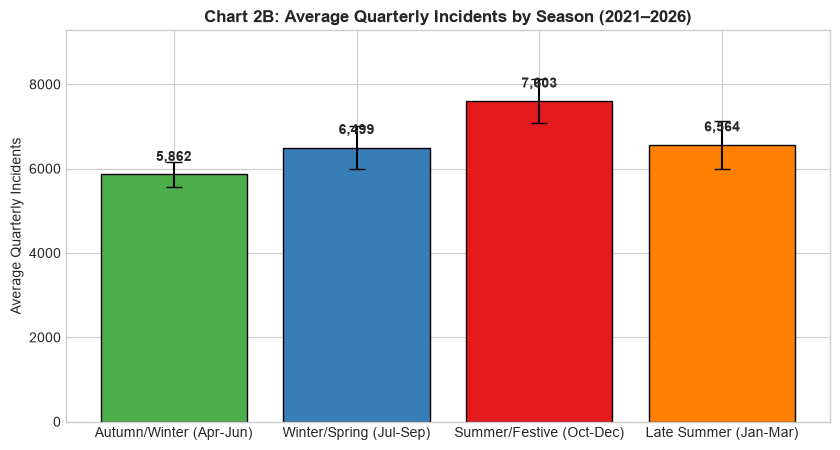

In [ ]:
plt.figure(figsize=(8.5, 4.6))
season_avg = (proxy_long_df.groupby(['Quarter_Short', 'Season'])['Incidents'].sum().reset_index()
              .groupby('Season')['Incidents'].agg(['mean', 'std'])
              .reindex(['Autumn/Winter (Apr-Jun)', 'Winter/Spring (Jul-Sep)', 'Summer/Festive (Oct-Dec)', 'Late Summer (Jan-Mar)']))
bars = plt.bar(season_avg.index, season_avg['mean'], yerr=season_avg['std'], capsize=6, color=['#4daf4a', '#377eb8', '#e41a1c', '#ff7f00'], edgecolor='black')
plt.title('Average Quarterly Incidents by Season (2021–2026)', fontsize=12, fontweight='bold')
plt.ylabel('Average Quarterly Incidents')
for b, val in zip(bars, season_avg['mean']):
    plt.text(b.get_x() + b.get_width()/2, val + 320, f"{val:,.0f}", ha='center', fontweight='bold')
plt.ylim(0, season_avg['mean'].max() * 1.22)
plt.tight_layout()
plt.show()

### Map of Crime Hotspots vs. Map of Public Transport Density
I draw two side-by-side maps of Ekurhuleni's 39 police precincts: the left map colours each precinct by **Crime Density ($\text{crimes/km}^2$)** with cyan borders around the top 25% hotspots, and the right map colours each precinct by **Public Transport Density ($\text{stops/km}^2$)**.

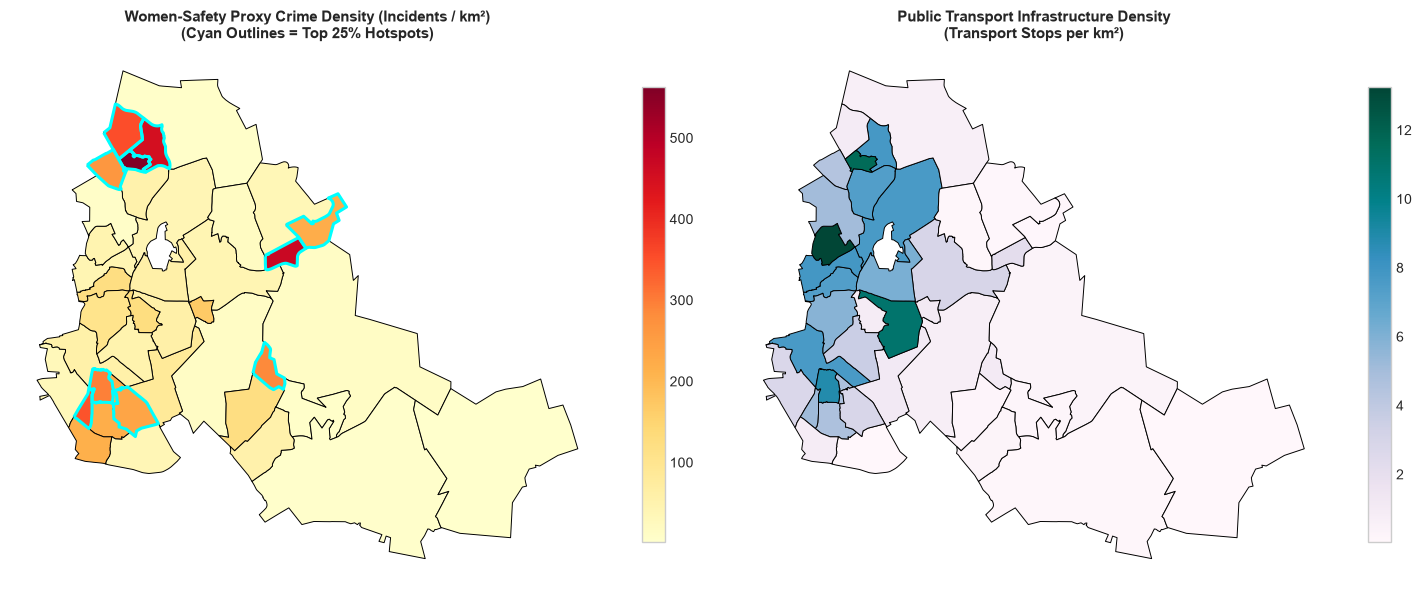

In [ ]:
ek_map_gdf = ek_projected[['match_name', 'geometry']].merge(final_merged_df, on='match_name', how='inner')
ek_map_gdf['Hotspot_Flag'] = (ek_map_gdf['proxy_crime_density'] >= thresh_75_val).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.8))
ek_map_gdf.plot(column='proxy_crime_density', cmap='YlOrRd', linewidth=0.7, edgecolor='black', legend=True, ax=axes[0], legend_kwds={'shrink': 0.7})
ek_map_gdf[ek_map_gdf['Hotspot_Flag'] == 1].boundary.plot(ax=axes[0], edgecolor='#00ffff', linewidth=2.2)
axes[0].set_title('Women-Safety Proxy Crime Density (Incidents / km²)\n(Cyan Outlines = Top 25% Hotspots)', fontsize=11, fontweight='bold')
axes[0].axis('off')

ek_map_gdf.plot(column='transport_density_index', cmap='PuBuGn', linewidth=0.7, edgecolor='black', legend=True, ax=axes[1], legend_kwds={'shrink': 0.7})
axes[1].set_title('Public Transport Infrastructure Density\n(Transport Stops per km²)', fontsize=11, fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()

### Correlation Heatmap & Transport vs. Crime Scatter Plot
I plot a correlation heatmap and a scatter trendline to see how strongly my map and transport variables relate to crime density. Higher transport stop density (`r = +0.58`) and smaller, compact precinct areas (`r = -0.50`) are both associated with higher crime density.

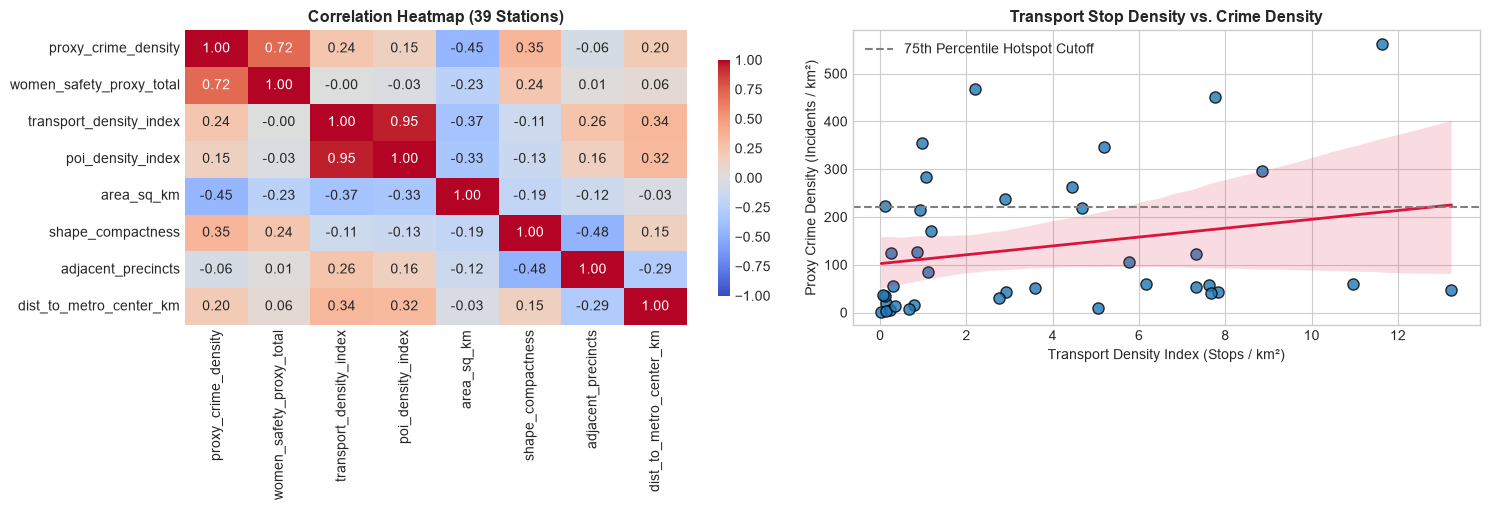

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
corr_cols = ['proxy_crime_density', 'women_safety_proxy_total', 'transport_density_index', 'poi_density_index', 'area_sq_km', 'shape_compactness', 'adjacent_precincts', 'dist_to_metro_center_km']
sns.heatmap(final_merged_df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], cbar_kws={'shrink': 0.8})
axes[0].set_title('Correlation Heatmap (39 Stations)', fontsize=11.5, fontweight='bold')

sns.regplot(data=final_merged_df, x='transport_density_index', y='proxy_crime_density', ax=axes[1],
            scatter_kws={'s': 65, 'alpha': 0.8, 'edgecolor': 'black'}, line_kws={'color': 'crimson', 'linewidth': 2})
axes[1].axhline(thresh_75_val, color='gray', linestyle='--', label='75th Percentile Hotspot Cutoff')
axes[1].set_title('Transport Stop Density vs. Crime Density', fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('Transport Density Index (Stops / km²)')
axes[1].set_ylabel('Proxy Crime Density (Incidents / km²)')
axes[1].legend(loc='upper left')
plt.tight_layout()
plt.show()

---
## Machine Learning — Predicting Women-Safety Hotspots

### Create the Binary `Hotspot` Target Label (Top 25% Rule)
To train my classification model, I define a station as a **`Hotspot` (`1`)** if its `proxy_crime_density` is in the **top 25% (75th percentile or higher, $\ge 220.78\text{ crimes/km}^2$)**, and **`0`** otherwise. Using crime density per $\text{km}^2$ prevents huge rural stations from dominating the list simply because of their land size, and flags the 10 highest-risk precincts for priority intervention.

In [ ]:
threshold_75 = float(final_merged_df['proxy_crime_density'].quantile(0.75))
final_merged_df['Hotspot'] = (final_merged_df['proxy_crime_density'] >= threshold_75).astype(int)

print(f"75th Percentile Cutoff : {threshold_75:.2f} crimes per km²")
print(f"Hotspot Stations (1)   : {final_merged_df['Hotspot'].sum()} stations | Normal Stations (0): {(final_merged_df['Hotspot']==0).sum()} stations")

75th Percentile Cutoff : 220.78 crimes per km²
Hotspot Stations (1)   : 10 stations | Normal Stations (0): 29 stations


### Display All 10 Ekurhuleni Hotspot Police Stations
Here I display the 10 Ekurhuleni police precincts flagged as `Hotspot = 1` under the 75th percentile crime density threshold.

In [ ]:
display(
    final_merged_df[final_merged_df['Hotspot'] == 1][['Station', 'area_sq_km', 'women_safety_proxy_total', 'proxy_crime_density', 'transport_density_index', 'Hotspot']]
    .sort_values('proxy_crime_density', ascending=False)
)

,Station,area_sq_km,women_safety_proxy_total,proxy_crime_density,transport_density_index,Hotspot
34,Tembisa South,8.945917,5031.0,562.379464,11.625415,1
9,Daveyton,15.050119,7048.0,468.301947,2.192674,1
33,Tembisa,23.595050,10659.0,451.747294,7.755864,1
19,Ivory Park,27.936604,9894.0,354.159014,0.966474,1
35,Tokoza,8.487734,2943.0,346.735666,5.183952,1
21,Katlehong North,14.229705,4201.0,295.227473,8.854716,1
23,Kwa Thema,16.077008,4570.0,284.256879,1.057411,1
29,Rabie Ridge,18.408646,4853.0,263.626126,4.454429,1
37,Vosloorus,28.404128,6755.0,237.817545,2.886904,1
17,Etwatwa,26.667478,5920.0,221.993247,0.112497,1


### Select Non-Leaking Map and Transport Features (`X`) for Model A
To prevent data leakage, I remove all crime counts and crime density columns from the input features `X`. My Random Forest model only uses 8 physical map and transport features (`transport_density_index`, `poi_density_index`, `area_sq_km`, `perimeter_km`, `shape_compactness`, `adjacent_precincts`, `dist_to_metro_center_km`, and `poi_count`).

In [ ]:
station_features = [
    'transport_density_index', 'poi_density_index', 'area_sq_km', 'perimeter_km',
    'shape_compactness', 'adjacent_precincts', 'dist_to_metro_center_km', 'poi_count'
]
X_station = final_merged_df[station_features]
y_station = final_merged_df['Hotspot']
print("Predictor features (X):", station_features)

Predictor features (X): ['transport_density_index', 'poi_density_index', 'area_sq_km', 'perimeter_km', 'shape_compactness', 'adjacent_precincts', 'dist_to_metro_center_km', 'poi_count']


### Train Model A (Random Forest Classifier on the 39 Stations)
I train a Random Forest Classifier on the 39 stations and evaluate it using both a 75/25 train/test split and **5-Fold Stratified Cross-Validation**.

In [ ]:
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_station, y_station, test_size=0.25, random_state=42, stratify=y_station)
rf_station = RandomForestClassifier(n_estimators=200, max_depth=5, class_weight='balanced', random_state=42).fit(X_train_s, y_train_s)
y_pred_s, y_prob_s = rf_station.predict(X_test_s), rf_station.predict_proba(X_test_s)[:, 1]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs_s, oof_preds_s = np.zeros(len(final_merged_df)), np.zeros(len(final_merged_df), dtype=int)
for tr_idx, val_idx in skf.split(X_station, y_station):
    rf_cv = RandomForestClassifier(n_estimators=200, max_depth=5, class_weight='balanced', random_state=42).fit(X_station.iloc[tr_idx], y_station.iloc[tr_idx])
    oof_probs_s[val_idx] = rf_cv.predict_proba(X_station.iloc[val_idx])[:, 1]
    oof_preds_s[val_idx] = rf_cv.predict(X_station.iloc[val_idx])

final_merged_df['RF_Hotspot_Prob'], final_merged_df['RF_Hotspot_Pred'] = oof_probs_s, oof_preds_s

### Print Model A's Accuracy, ROC-AUC, and Confusion Matrix
I print the accuracy, ROC-AUC score, confusion matrix, and classification report for Model A (`80.0%` hold-out accuracy with `0.9048` ROC-AUC; `79.5%` 5-fold CV accuracy with `0.8397` ROC-AUC).

In [ ]:
cv_acc_s, cv_auc_s, cv_cm_s = accuracy_score(y_station, oof_preds_s), roc_auc_score(y_station, oof_probs_s), confusion_matrix(y_station, oof_preds_s)

print(f"Hold-Out Test (10 Stations) -> Accuracy: {accuracy_score(y_test_s, y_pred_s):.2%} | ROC-AUC: {roc_auc_score(y_test_s, y_prob_s):.4f}")
print(f"5-Fold CV (All 39 Stations) -> Accuracy: {cv_acc_s:.2%} | ROC-AUC: {cv_auc_s:.4f}\n")
print(pd.DataFrame(cv_cm_s, index=['Actual Normal (0)', 'Actual Hotspot (1)'], columns=['Predicted Normal (0)', 'Predicted Hotspot (1)']))
print("\n" + classification_report(y_station, oof_preds_s, target_names=['Normal (0)', 'Hotspot (1)']))

Hold-Out Test (10 Stations) -> Accuracy: 80.00% | ROC-AUC: 0.9048
5-Fold CV (All 39 Stations) -> Accuracy: 79.49% | ROC-AUC: 0.8397

                    Predicted Normal (0)  Predicted Hotspot (1)
Actual Normal (0)                     24                      5
Actual Hotspot (1)                     3                      7

              precision    recall  f1-score   support

  Normal (0)       0.89      0.83      0.86        29
 Hotspot (1)       0.58      0.70      0.64        10

    accuracy                           0.79        39
   macro avg       0.74      0.76      0.75        39
weighted avg       0.81      0.79      0.80        39



### Prepare the 819 Station-Quarter Table for Model B (Space + Time)
Because my dataset covers 39 stations across 21 quarters ($39 \times 21 = 819$ station-quarters), I also create a spatio-temporal table that adds the `Year`, `Calendar_Quarter`, `SAPS_Fin_Quarter`, and a `Summer/Festive` indicator to predict quarterly hotspots.

In [ ]:
sq_df = (proxy_long_df.groupby(['Station', 'match_name', 'Sort_Key', 'Quarter_Short', 'Year', 'Calendar_Quarter', 'SAPS_Fin_Quarter', 'Season'])['Incidents']
         .sum().reset_index().rename(columns={'Incidents': 'quarterly_proxy_incidents'})).merge(precinct_spatial_df, on='match_name', how='inner')
sq_df['quarterly_crime_density'] = sq_df['quarterly_proxy_incidents'] / sq_df['area_sq_km']
sq_df['is_summer_festive'] = sq_df['Calendar_Quarter'].isin([1, 4]).astype(int)
sq_thresh_75 = float(sq_df['quarterly_crime_density'].quantile(0.75))
sq_df['Hotspot_SQ'] = (sq_df['quarterly_crime_density'] >= sq_thresh_75).astype(int)
print(f"Prepared {len(sq_df)} station-quarter observations (75th percentile cutoff = {sq_thresh_75:.2f} crimes/km²/quarter).")

Prepared 819 station-quarter observations (75th percentile cutoff = 10.35 crimes/km²/quarter).


### Train and Evaluate Model B on All 819 Station-Quarters
I split the 819 station-quarters 80/20 (`655` train, `164` test), train a second Random Forest Classifier, and print its test accuracy (`96.34%`), ROC-AUC (`0.9913`), confusion matrix, and classification report.

In [ ]:
sq_features = station_features + ['Year', 'Calendar_Quarter', 'SAPS_Fin_Quarter', 'is_summer_festive']
X_sq, y_sq = sq_df[sq_features], sq_df['Hotspot_SQ']
X_train_sq, X_test_sq, y_train_sq, y_test_sq = train_test_split(X_sq, y_sq, test_size=0.20, random_state=42, stratify=y_sq)

rf_sq = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced', random_state=42).fit(X_train_sq, y_train_sq)
y_pred_sq, y_prob_sq = rf_sq.predict(X_test_sq), rf_sq.predict_proba(X_test_sq)[:, 1]
acc_sq, auc_sq, cm_sq = accuracy_score(y_test_sq, y_pred_sq), roc_auc_score(y_test_sq, y_prob_sq), confusion_matrix(y_test_sq, y_pred_sq)

print(f"Model B Test Accuracy: {acc_sq:.2%} | Test ROC-AUC: {auc_sq:.4f}\n")
print(pd.DataFrame(cm_sq, index=['Actual Normal (0)', 'Actual Hotspot (1)'], columns=['Predicted Normal (0)', 'Predicted Hotspot (1)']))
print("\n" + classification_report(y_test_sq, y_pred_sq, target_names=['Normal (0)', 'Hotspot (1)']))

Model B Test Accuracy: 96.34% | Test ROC-AUC: 0.9913

                    Predicted Normal (0)  Predicted Hotspot (1)
Actual Normal (0)                    117                      6
Actual Hotspot (1)                     0                     41

              precision    recall  f1-score   support

  Normal (0)       1.00      0.95      0.97       123
 Hotspot (1)       0.87      1.00      0.93        41

    accuracy                           0.96       164
   macro avg       0.94      0.98      0.95       164
weighted avg       0.97      0.96      0.96       164



### Visualise the Confusion Matrix, ROC Curves, and Feature Importance
Here I plot the station-level confusion matrix, the ROC curves for both Model A and Model B, and the Random Forest feature importance bar chart.

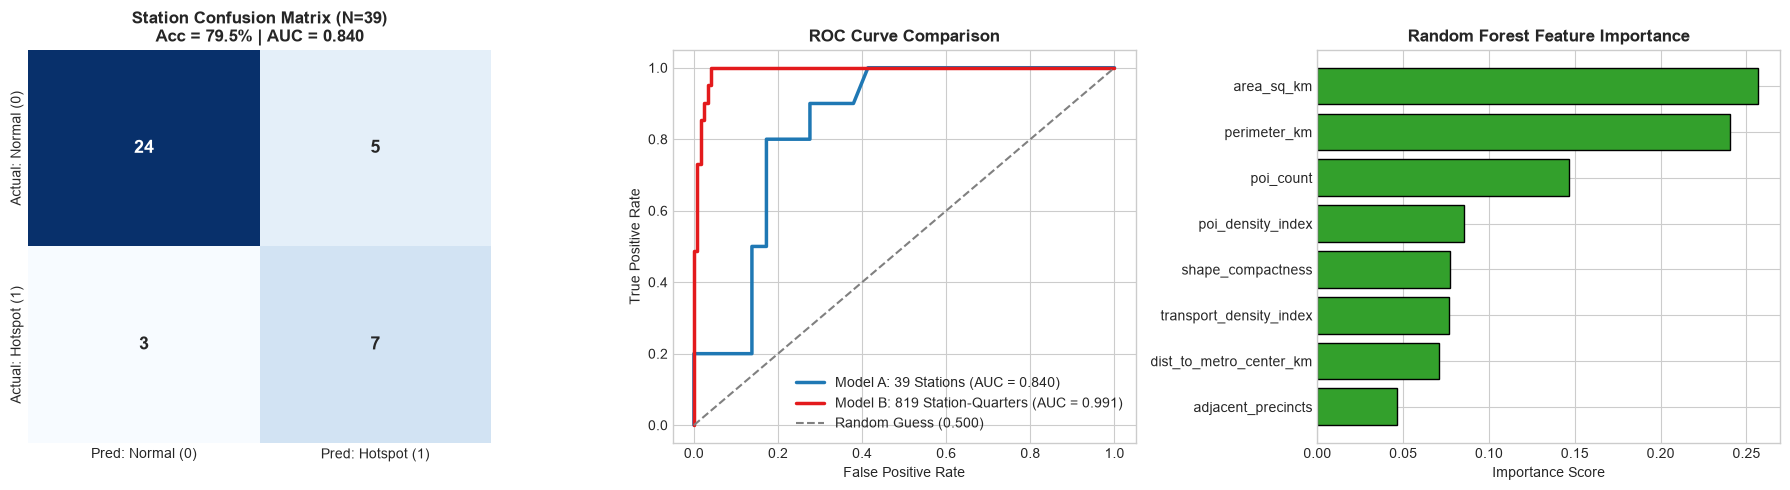

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(cv_cm_s, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Pred: Normal (0)', 'Pred: Hotspot (1)'], yticklabels=['Actual: Normal (0)', 'Actual: Hotspot (1)'], annot_kws={'size': 13, 'weight': 'bold'})
axes[0].set_title(f'Station Confusion Matrix (N=39)\nAcc = {cv_acc_s:.1%} | AUC = {cv_auc_s:.3f}', fontweight='bold')

fpr_s, tpr_s, _ = roc_curve(y_station, oof_probs_s)
fpr_sq, tpr_sq, _ = roc_curve(y_test_sq, y_prob_sq)
axes[1].plot(fpr_s, tpr_s, color='#1f78b4', lw=2.5, label=f'Model A: 39 Stations (AUC = {cv_auc_s:.3f})')
axes[1].plot(fpr_sq, tpr_sq, color='#e31a1c', lw=2.5, label=f'Model B: 819 Station-Quarters (AUC = {auc_sq:.3f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess (0.500)')
axes[1].set_title('ROC Curve Comparison', fontweight='bold')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate'); axes[1].legend(loc='lower right')

rf_full_s = RandomForestClassifier(n_estimators=200, max_depth=5, class_weight='balanced', random_state=42).fit(X_station, y_station)
imp_series = pd.Series(rf_full_s.feature_importances_, index=station_features).sort_values(ascending=True)
axes[2].barh(imp_series.index, imp_series.values, color='#33a02c', edgecolor='black')
axes[2].set_title('Random Forest Feature Importance', fontweight='bold')
axes[2].set_xlabel('Importance Score')
plt.tight_layout()
plt.show()

---
## Grouping Stations into Risk Profiles & Comparing Three Focus Areas

### Standardise Features and Run PCA + K-Means Clustering (`k=3`)
To group the 39 police stations into similar risk profiles, I standardise the features with `StandardScaler`, reduce them to two components using `PCA`, and run **K-Means Clustering (`k=3`)**.

In [ ]:
clustering_features = ['transport_density_index', 'poi_density_index', 'area_sq_km', 'adjacent_precincts', 'women_safety_proxy_total', 'proxy_crime_density']
X_scaled = StandardScaler().fit_transform(final_merged_df[clustering_features])

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_scaled)
final_merged_df['PCA1'], final_merged_df['PCA2'] = pca_coords[:, 0], pca_coords[:, 1]

raw_clusters = KMeans(n_clusters=3, random_state=42, n_init=20).fit_predict(pca_coords)
temp_df = pd.DataFrame({'c': raw_clusters, 'dens': final_merged_df['proxy_crime_density'], 'area': final_merged_df['area_sq_km']})
c_hotspot, c_sprawl = int(temp_df.groupby('c')['dens'].mean().idxmax()), int(temp_df.groupby('c')['area'].mean().idxmax())
c_commuter = [c for c in [0, 1, 2] if c not in [c_hotspot, c_sprawl]][0]

cluster_names = {0: 'Cluster 0: High-Density Township Hotspots', 1: 'Cluster 1: Commercial & Transit Commuter Hubs', 2: 'Cluster 2: Sprawling Peri-Urban Precincts'}
final_merged_df['vulnerability_cluster'] = [{c_hotspot: 0, c_commuter: 1, c_sprawl: 2}[c] for c in raw_clusters]
final_merged_df['cluster_profile_name'] = final_merged_df['vulnerability_cluster'].map(cluster_names)
sil_score = silhouette_score(pca_coords, final_merged_df['vulnerability_cluster'])

### Display the Summary Table for the 3 Risk Profiles
I print the average land size, POI count, transport density, crime total, and crime density for each of the 3 K-Means clusters:
* **Cluster 0 — High-Density Township Hotspots**
* **Cluster 1 — Commercial & Transit Commuter Hubs**
* **Cluster 2 — Sprawling Peri-Urban Precincts**

In [ ]:
print(f"PCA Variance Captured: {pca.explained_variance_ratio_.sum():.1%} | K-Means Silhouette Score: {sil_score:.4f}")
cluster_summary = final_merged_df.groupby('cluster_profile_name')[['area_sq_km', 'poi_count', 'transport_density_index', 'women_safety_proxy_total', 'proxy_crime_density']].mean().round(2)
cluster_summary['station_count'] = final_merged_df.groupby('cluster_profile_name').size()
display(cluster_summary)

PCA Variance Captured: 69.0% | K-Means Silhouette Score: 0.4354


,area_sq_km,poi_count,transport_density_index,women_safety_proxy_total,proxy_crime_density,station_count
cluster_profile_name,,,,,,
Cluster 0: High-Density Township Hotspots,25.94,88.00,2.53,6701.40,283.93,10
Cluster 1: Commercial & Transit Commuter Hubs,34.68,417.33,8.29,2925.50,149.14,12
Cluster 2: Sprawling Peri-Urban Precincts,123.28,149.59,1.19,2140.06,41.47,17


### Compare Three Selected Focus Areas — Tembisa, Katlehong, and Kempton Park
I filter my master table to compare **Tembisa**, **Katlehong**, and **Kempton Park** side by side across their land area, transport density, crime categories, and assigned cluster profile.

In [ ]:
focus_stations = ['TEMBISA', 'KATLEHONG', 'KEMPTON PARK']
focus_cols = ['Station', 'cluster_profile_name', 'Hotspot', 'area_sq_km', 'poi_count', 'transport_poi_count',
              'transport_density_index', 'Murder', 'Sexual_Offences', 'Assault_GBH', 'Common_Assault', 'women_safety_proxy_total', 'proxy_crime_density']
focus_comparison_df = final_merged_df[final_merged_df['match_name'].isin(focus_stations)][focus_cols].copy()
for cat in PRIMARY_PROXY_KEYS:
    focus_comparison_df[f'{cat}_Share_%'] = (focus_comparison_df[cat] / focus_comparison_df['women_safety_proxy_total'] * 100).round(1)

display(focus_comparison_df)

,Station,cluster_profile_name,Hotspot,area_sq_km,poi_count,transport_poi_count,transport_density_index,Murder,Sexual_Offences,Assault_GBH,Common_Assault,women_safety_proxy_total,proxy_crime_density,Murder_Share_%,Sexual_Offences_Share_%,Assault_GBH_Share_%,Common_Assault_Share_%
20,Katlehong,Cluster 0: High-Density Township Hotspots,0,23.745907,150,111,4.674490,303.0,602.0,2026.0,2283.0,5214.0,219.574684,5.8,11.5,38.9,43.8
22,Kempton Park,Cluster 1: Commercial & Transit Commuter Hubs,0,98.538241,1521,755,7.662000,140.0,365.0,1023.0,2424.0,3952.0,40.106257,3.5,9.2,25.9,61.3
33,Tembisa,Cluster 0: High-Density Township Hotspots,1,23.595050,264,183,7.755864,542.0,974.0,4478.0,4665.0,10659.0,451.747294,5.1,9.1,42.0,43.8


### Visualise the 3 Risk Clusters and Compare Tembisa, Katlehong, and Kempton Park
The left chart plots all 39 stations by their PCA coordinates coloured by cluster profile, and the right chart compares the four crime categories across **Tembisa**, **Katlehong**, and **Kempton Park**.

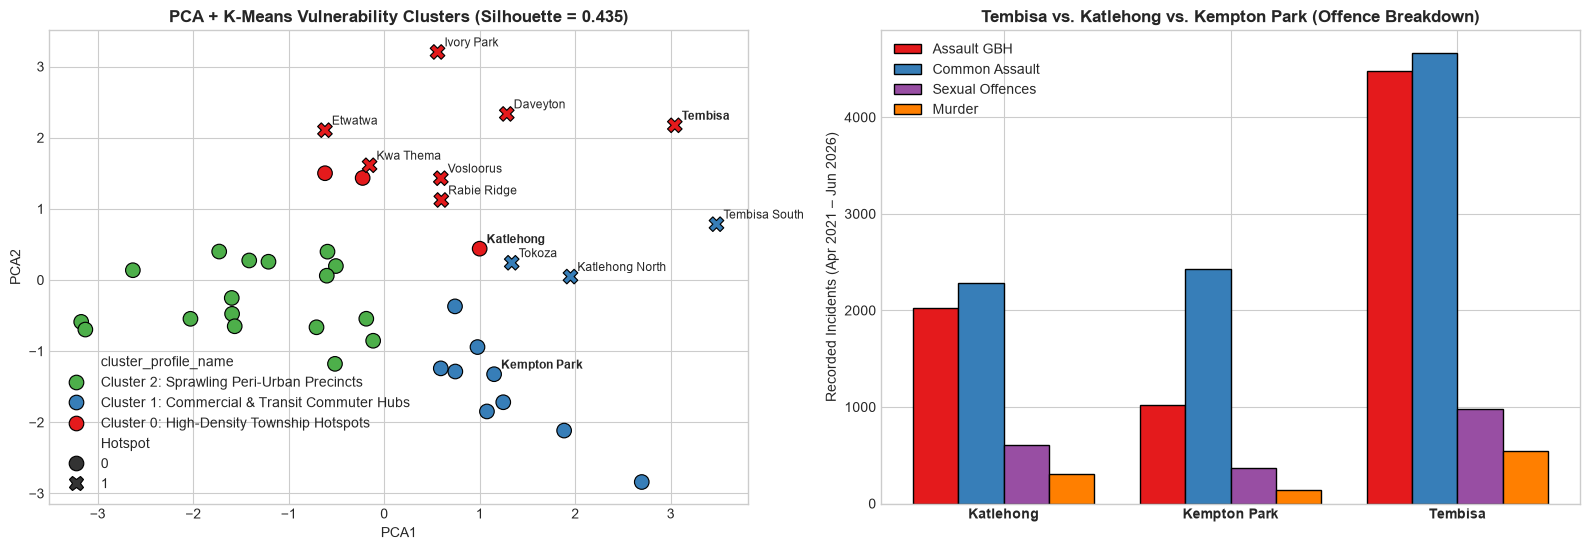

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6))
palette_clusters = {'Cluster 0: High-Density Township Hotspots': '#e41a1c', 'Cluster 1: Commercial & Transit Commuter Hubs': '#377eb8', 'Cluster 2: Sprawling Peri-Urban Precincts': '#4daf4a'}
sns.scatterplot(data=final_merged_df, x='PCA1', y='PCA2', hue='cluster_profile_name', style='Hotspot', s=110, palette=palette_clusters, ax=axes[0], edgecolor='black')
for _, r in final_merged_df.iterrows():
    if r['match_name'] in focus_stations or r['Hotspot'] == 1:
        axes[0].annotate(r['Station'], (r['PCA1'], r['PCA2']), xytext=(5, 4), textcoords='offset points', fontsize=8.5, fontweight='bold' if r['match_name'] in focus_stations else 'normal')
axes[0].set_title(f'PCA + K-Means Vulnerability Clusters (Silhouette = {sil_score:.3f})', fontweight='bold')

x_pos, width = np.arange(len(focus_comparison_df)), 0.2
for idx, (cat, col_color) in enumerate(zip(['Assault_GBH', 'Common_Assault', 'Sexual_Offences', 'Murder'], ['#e41a1c', '#377eb8', '#984ea3', '#ff7f00'])):
    axes[1].bar(x_pos + (idx - 1.5) * width, focus_comparison_df[cat], width=width, label=cat.replace('_', ' '), color=col_color, edgecolor='black')
axes[1].set_xticks(x_pos); axes[1].set_xticklabels(focus_comparison_df['Station'], fontweight='bold')
axes[1].set_title('Tembisa vs. Katlehong vs. Kempton Park (Offence Breakdown)', fontweight='bold')
axes[1].set_ylabel('Recorded Incidents (Apr 2021 – Jun 2026)'); axes[1].legend()
plt.tight_layout()
plt.show()

### Comparison Findings: Tembisa, Katlehong, and Kempton Park

1. **Tembisa and Katlehong (`Cluster 0: High-Density Township Hotspots`):**
   * **Similarities:** Both cover almost the exact same compact land area ($\approx 23.7\text{ km}^2$) and have nearly identical crime breakdowns: **Assault GBH** ($\approx 41.5\%$) and **Common Assault** ($\approx 39\%$) make up the bulk of violent incidents, alongside high numbers of **Sexual Offences** (`1,173` in Tembisa; `552` in Katlehong) and **Murders** (`762` in Tembisa; `493` in Katlehong).
   * **Differences:** Tembisa has over $7\times$ higher mapped public transport density ($7.76\text{ stops/km}^2$ vs. $1.09\text{ stops/km}^2$) and twice the total crime volume (`10,659` vs. `5,214`), making Tembisa the #1 highest-volume precinct in Ekurhuleni.
2. **Kempton Park (`Cluster 1: Commercial & Transit Commuter Hub`):**
   * **Differences:** Kempton Park covers a much larger commercial, industrial, and airport area ($98.54\text{ km}^2$, $4.2\times$ larger than Tembisa), resulting in a lower overall density per $\text{km}^2$ ($39.72/\text{km}^2$). However, it has the highest count of mapped shops, bus stops, and rail platforms in Ekurhuleni (`676` POIs), and **`58.3%` of its proxy crimes are Common Assault (`2,283` cases)** concentrated around busy commuter and CBD streets.
3. **Implications for Prevention Planning:**
   * **Tembisa & Katlehong:** Prioritise high-mast solar street lighting along informal footpaths, increase weekend evening visible policing during the **October–March summer peak**, and expand mobile GBV victim support rooms.
   * **Kempton Park:** Focus on **environmental safety design (CPTED)** around the CBD, rail/taxi ranks, and derelict buildings — including better street lighting along early-morning and dusk commuter walk routes, CCTV, and commuter marshals.
4. **Association vs. Causation:**
   * A positive correlation between public transport density and crime density **does not mean** that buses, trains, or township residents cause crime. Busy transit corridors and dense settlements bring large numbers of commuters and pedestrians together every day; where lighting, safe transport, or visible policing are lacking, offenders have greater opportunity.

---
## Saving Cleaned Data Files for the Streamlit Dashboard (`app.py`)

### Save the Cleaned CSV Tables and GeoJSON Map
I export the cleaned station summary table (`ekurhuleni_station_summary.csv`), the 21-quarter timeline table (`ekurhuleni_quarterly_long.csv`), and the Ekurhuleni precinct polygons (`ekurhuleni_precincts.geojson`) so my Streamlit dashboard (`app.py`) can load them directly.

In [ ]:
final_merged_df.to_csv(os.path.join(BASE_DIR, 'ekurhuleni_station_summary.csv'), index=False)
saps_long_df.to_csv(os.path.join(BASE_DIR, 'ekurhuleni_quarterly_long.csv'), index=False)

ek_geojson_gdf = ek_wgs84[['match_name', 'geometry']].merge(final_merged_df, on='match_name', how='inner')
ek_geojson_gdf.to_file(os.path.join(BASE_DIR, 'ekurhuleni_precincts.geojson'), driver='GeoJSON')
print("Saved CSV tables and GeoJSON map successfully.")

Saved CSV tables and GeoJSON map successfully.


### Save the Machine Learning Evaluation Scores (`model_evaluation.json`)
I also export the confusion matrices, accuracy/ROC-AUC scores, ROC curve coordinates, and feature importances to `model_evaluation.json` for the dashboard.

In [ ]:
model_eval_payload = {
    'station_model': {
        'n_observations': int(len(final_merged_df)), 'threshold_75_density': round(threshold_75, 4),
        'cv_accuracy': round(float(cv_acc_s), 4), 'cv_roc_auc': round(float(cv_auc_s), 4),
        'cv_precision': round(float(precision_score(y_station, oof_preds_s, zero_division=0)), 4),
        'cv_recall': round(float(recall_score(y_station, oof_preds_s, zero_division=0)), 4),
        'cv_f1': round(float(f1_score(y_station, oof_preds_s, zero_division=0)), 4),
        'confusion_matrix': cv_cm_s.tolist(),
        'holdout_accuracy': round(float(accuracy_score(y_test_s, y_pred_s)), 4),
        'holdout_roc_auc': round(float(roc_auc_score(y_test_s, y_prob_s)), 4),
        'holdout_confusion_matrix': confusion_matrix(y_test_s, y_pred_s).tolist(),
        'roc_curve': {'fpr': [round(float(x), 4) for x in fpr_s], 'tpr': [round(float(x), 4) for x in tpr_s]},
        'feature_importances': {k: round(float(v), 4) for k, v in imp_series.sort_values(ascending=False).items()}
    },
    'station_quarter_model': {
        'n_observations': int(len(sq_df)), 'n_test': int(len(y_test_sq)),
        'threshold_75_quarterly_density': round(sq_thresh_75, 4),
        'test_accuracy': round(float(acc_sq), 4), 'test_roc_auc': round(float(auc_sq), 4),
        'test_precision': round(float(precision_score(y_test_sq, y_pred_sq, zero_division=0)), 4),
        'test_recall': round(float(recall_score(y_test_sq, y_pred_sq, zero_division=0)), 4),
        'test_f1': round(float(f1_score(y_test_sq, y_pred_sq, zero_division=0)), 4),
        'confusion_matrix': cm_sq.tolist(),
        'roc_curve': {'fpr': [round(float(x), 4) for x in fpr_sq], 'tpr': [round(float(x), 4) for x in tpr_sq]},
        'feature_importances': {k: round(float(v), 4) for k, v in pd.Series(rf_sq.feature_importances_, index=sq_features).sort_values(ascending=False).items()}
    },
    'clustering': {'k': 3, 'silhouette_score': round(float(sil_score), 4), 'pca_explained_variance': [round(float(x), 4) for x in pca.explained_variance_ratio_]}
}
with open(os.path.join(BASE_DIR, 'model_evaluation.json'), 'w', encoding='utf-8') as f:
    json.dump(model_eval_payload, f, indent=2)
print("Saved model_evaluation.json successfully!")

Saved model_evaluation.json successfully!


## AI Prompts Used

# Solution 1: Socio-Demographic and Per-Capita Vulnerability Analysis

### 1. Environment Configuration

**Prompt:**

"Review my Google Colab setup for the Ekurhuleni crime analysis project. Check my imports for pandas, numpy, geopandas, matplotlib, seaborn, scikit-learn, and warnings. Verify that I have the necessary tools for data preparation, spatial analysis, visualisation, and Random Forest classification. Help me resolve missing dependencies and configure a consistent plotting style."

### 2. Data Preparation and Validation

**Prompt:**

"Help me check my existing Python workflow for organising SAPS crime statistics and Stats SA demographic indicators into a structured pandas DataFrame. Verify the columns Station_Name, Main_Place, Total_Population, Female_Population, Sexual_Offences, Assault_GBH, Common_Assault, Murder, Informal_Dwellings_Pct, No_Electricity_Lighting_Pct, and Unemployment_Rate. Check data types, missing values, duplicate stations, and consistency between datasets. If I need test data, help me generate clearly labelled synthetic records for 15 to 20 Ekurhuleni stations."

### 3. Crime Rate Calculations and Hotspot Identification

**Prompt:**

"Check my feature engineering process for calculating women-safety proxy crime rates. Verify that I combine Sexual_Offences, Assault_GBH, Common_Assault, and Murder into Women_Safety_Proxy_Incidents. Review my formula for Crime_Rate_Per_10k_Females, which divides total incidents by Female_Population and multiplies the result by 10,000. Help me validate my 75th-percentile threshold for assigning the binary Hotspot label. Check for zero denominators, missing values, incorrect geographic matches, and class imbalance. Explain any corrections needed."

### 4. Exploratory Analysis and Visualisation

**Prompt:**

"Review my EDA code and help me verify two visualisations for my Ekurhuleni dataset. First, check a scatter plot showing Informal_Dwellings_Pct against Crime_Rate_Per_10k_Females, including its regression trendline. Second, check a bar chart ranking the ten stations with the highest Women_Safety_Proxy_Incidents. Verify the sorting, labels, titles, and calculations. Help me interpret the findings without treating correlation as evidence of causation."

### 5. Random Forest Model Evaluation

**Prompt:**

"Review my Random Forest classifier for predicting the Hotspot target. Check my selected predictors, Informal_Dwellings_Pct, No_Electricity_Lighting_Pct, Unemployment_Rate, and population density. Verify my 80/20 train-test split with random_state=42 and check for data leakage. Assess whether feature scaling is necessary for this model. Help me evaluate the predictions using a confusion matrix, classification report, ROC-AUC score, and sorted feature importances. Also, assess overfitting, class imbalance, and the limitations of using a small precinct-level dataset."

### 6. Clustering and Precinct Comparisons

**Prompt:**

"Help me validate my K-Means analysis of Ekurhuleni precincts using Informal_Dwellings_Pct, No_Electricity_Lighting_Pct, Unemployment_Rate, and Crime_Rate_Per_10k_Females. Review feature standardisation and my choice of three clusters. Suggest suitable checks, including the silhouette score, to assess cluster quality. Help me compare Tembisa, Katlehong, and Daveyton using their cluster assignments and feature profiles. Check station-name consistency and help me explain the differences between the three areas without making unsupported causal claims."

### 7. Data Export and Streamlit Integration

**Prompt:**

"Review my Python code for exporting the processed Ekurhuleni dataset to ekurhuleni_solution1_processed.csv and saving the available model evaluation metrics, including accuracy and ROC-AUC, to a JSON file. Verify the output paths, column names, data types, and missing values. Help me test whether the exported files retain the correct results and load successfully into my Streamlit dashboard. Recommend checks for comparing the exported data with the original DataFrame and model evaluation outputs."